In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 9.1 重ね合わせ処理 (`osbook_day09a`)

本節では、名著『ゼロからのOS自作入門』第9章「重ね合わせ処理」の扉を開き、モダンなグラフィカル・ユーザー・インターフェース（GUI）OSの根幹を支える**「レイヤ重ね合わせ（Layer Compositing）」**と**「画家アルゴリズム（Painter's Algorithm）」**の設計思想・理論導出・C++20実装を徹底解説します。

---

## 🎯 本節の学習到達目標

1. **第8章までの実装が抱えていた致命的課題:「背景破壊問題（Background Destruction Problem）」の根本原因究明**:
   - 第6章〜第8章までのマウスカーソル描画方式（直前位置の単色矩形塗りつぶしによる消去）が、なぜ背景文字やウィンドウを永久に破壊してしまうのか？
   - 単純な「背景退避バッファ（スプライト保存方式）」が抱えるマルチウィンドウ環境での破綻と状態爆発。
2. **重ね合わせ処理（Layer Compositing）と画家アルゴリズム（Painter's Algorithm）の理論導出**:
   - 画面全体を独立したオフスクリーン描画層（**Layer**）のスタック（重なり順: Z-order）としてモデル化。
   - 奥（最背面: Background）から手前（最前面: Mouse Cursor）へと順番にピクセルを上書き転送するレンダリング数理。
   - 透過色（Transparent Color / Color Keying）とクリッピング条件の完全導出。
3. **MikanOS 第9章のコア設計（3大クラス構成）の解剖**:
   - 2次元座標ベクトル: `Vector2D<T>`（演算子オーバーロードと型安全な座標計算）。
   - オフスクリーン描画領域: `Window`（2次元ピクセル配列、内部クラス `WindowWriter`、透過色 `transparent_color_`）。
   - レイヤ表現: `Layer`（レイヤID、表示座標 `pos_`、`std::shared_ptr<Window>` による参照所有）。
   - 全体調停・スタック管理: `LayerManager`（所有コンテナ `layers_`、重なり順スタック `layer_stack_`、`UpDown` / `Hide` / `Draw`）。
4. **第9章全体の開発ロードマップの把握**:
   - 9.1 重ね合わせ処理の基本思想 $\rightarrow$ 9.2 動的メモリ確保（`new` / `sbrk`） $\rightarrow$ 9.3 原理とスマートポインタ $\rightarrow$ 9.4 性能計測 $\rightarrow$ 9.5 矩形交差判定による差分再描画最適化。


---

## 1. なぜ「重ね合わせ処理」が必要なのか？（背景と動機）

### 第8章までのマウス描画の限界
第6章でマウス入力を実装し、第7章・第8章で割り込みとメモリ管理を組み込んできましたが、これまでのマウス描画には**致命的な欠陥**が存在していました。

マウスが移動する際、OS は以下の手順を踏んでいました：
1. 直前のマウスカーソル位置 $(x_{\text{old}}, y_{\text{old}})$ に、背景色（デスクトップの青色 `#2D76ED` など）の単色矩形を塗りつぶして消去する。
2. 新しいマウスカーソル位置 $(x_{\text{new}}, y_{\text{new}})$ に、マウスカーソルのピクセルパターンを描画する。

この単純なアプローチは、**「マウスカーソルの背後に何もない（単色背景だけ）」という極めて特殊な状況下でしか動作しません**。
もし画面上にコンソールの文字列（`printk("Welcome to MikanOS!\n")`）や、アプリケーションのウィンドウ、描画された図形が存在する場合、**マウスカーソルがその上を通過するだけで文字やウィンドウが青色で塗りつぶされ、二度と復元できなくなります**（いわゆる**背景破壊問題**）。

```
【従来の消去方式による文字消失シーケンス】
[初期状態]     画面: [ 青色背景 ] + [ 白い文字 'A' ]
                      ↓
[マウス通過]   マウスが文字 'A' の上に重なって黒く描画される
                      ↓
[マウス移動]   旧位置を「青色」で塗りつぶして消去！
                      ↓
[破壊完了]     文字 'A' は消滅し、青色の穴があく（永久喪失！）💥
```

### なぜ「一時退避バッファ（スプライト保存方式）」ではダメなのか？
ゲーム機などでよく使われる古典的な手法として、「マウスを描画する直前に、その背後にあるピクセルをメモリへ一時保存しておき、マウス移動時に書き戻す」という方式（スプライトバックアップ）があります。
しかし、汎用マルチタスク OS においてはこの手法は破綻します：
- 背後のウィンドウがタイマや別スレッドによって自律更新（時計アプリ、カウンタ、ログ出力など）された場合、書き戻す情報が古くなって画面が乱れる。
- 複数のウィンドウが重なり合い、ドラッグ＆ドロップで同時に移動する場合、退避バッファの競合や状態管理が指数関数的に複雑化する（状態爆発）。

### 根本的解決策: 画家アルゴリズム (Painter's Algorithm)
油絵を描く画家を想像してください。画家は、遠くの風景（空や山）をまずキャンバス一面に描き、その上に建物や木々を描き、最後に最も手前にある人物を描きます。
この順序で描けば、手前の人物が奥の風景を自然に覆い隠し、かつ風景を消す必要もありません。

OS の画面描画もまったく同じです。
1. **画面の要素を独立したレイヤ（Layer）に分ける**:
   - **Layer 0（最背面）**: デスクトップ背景・壁紙
   - **Layer 1（中間層）**: コンソール・ウィンドウ
   - **Layer 2（最前面）**: マウスカーソル
2. **各レイヤは独立した描画メモリ（オフスクリーンバッファ）を保持する**。
3. マウスが移動したら、**奥のレイヤから手前のレイヤへと順番に全レイヤを VRAM（フレームバッファ）へ重ね描き（Composite）する**。

このアプローチを採用すれば、マウスがどこへ移動しようとも、背後の文字やウィンドウの元データ（オフスクリーンバッファ）は1ピクセルも破壊されません。奥から描き直すだけで、文字は完全に元の姿で復元されます！

---

### Figure 9.01: 背景破壊問題 vs レイヤ重ね合わせ処理の原理対比


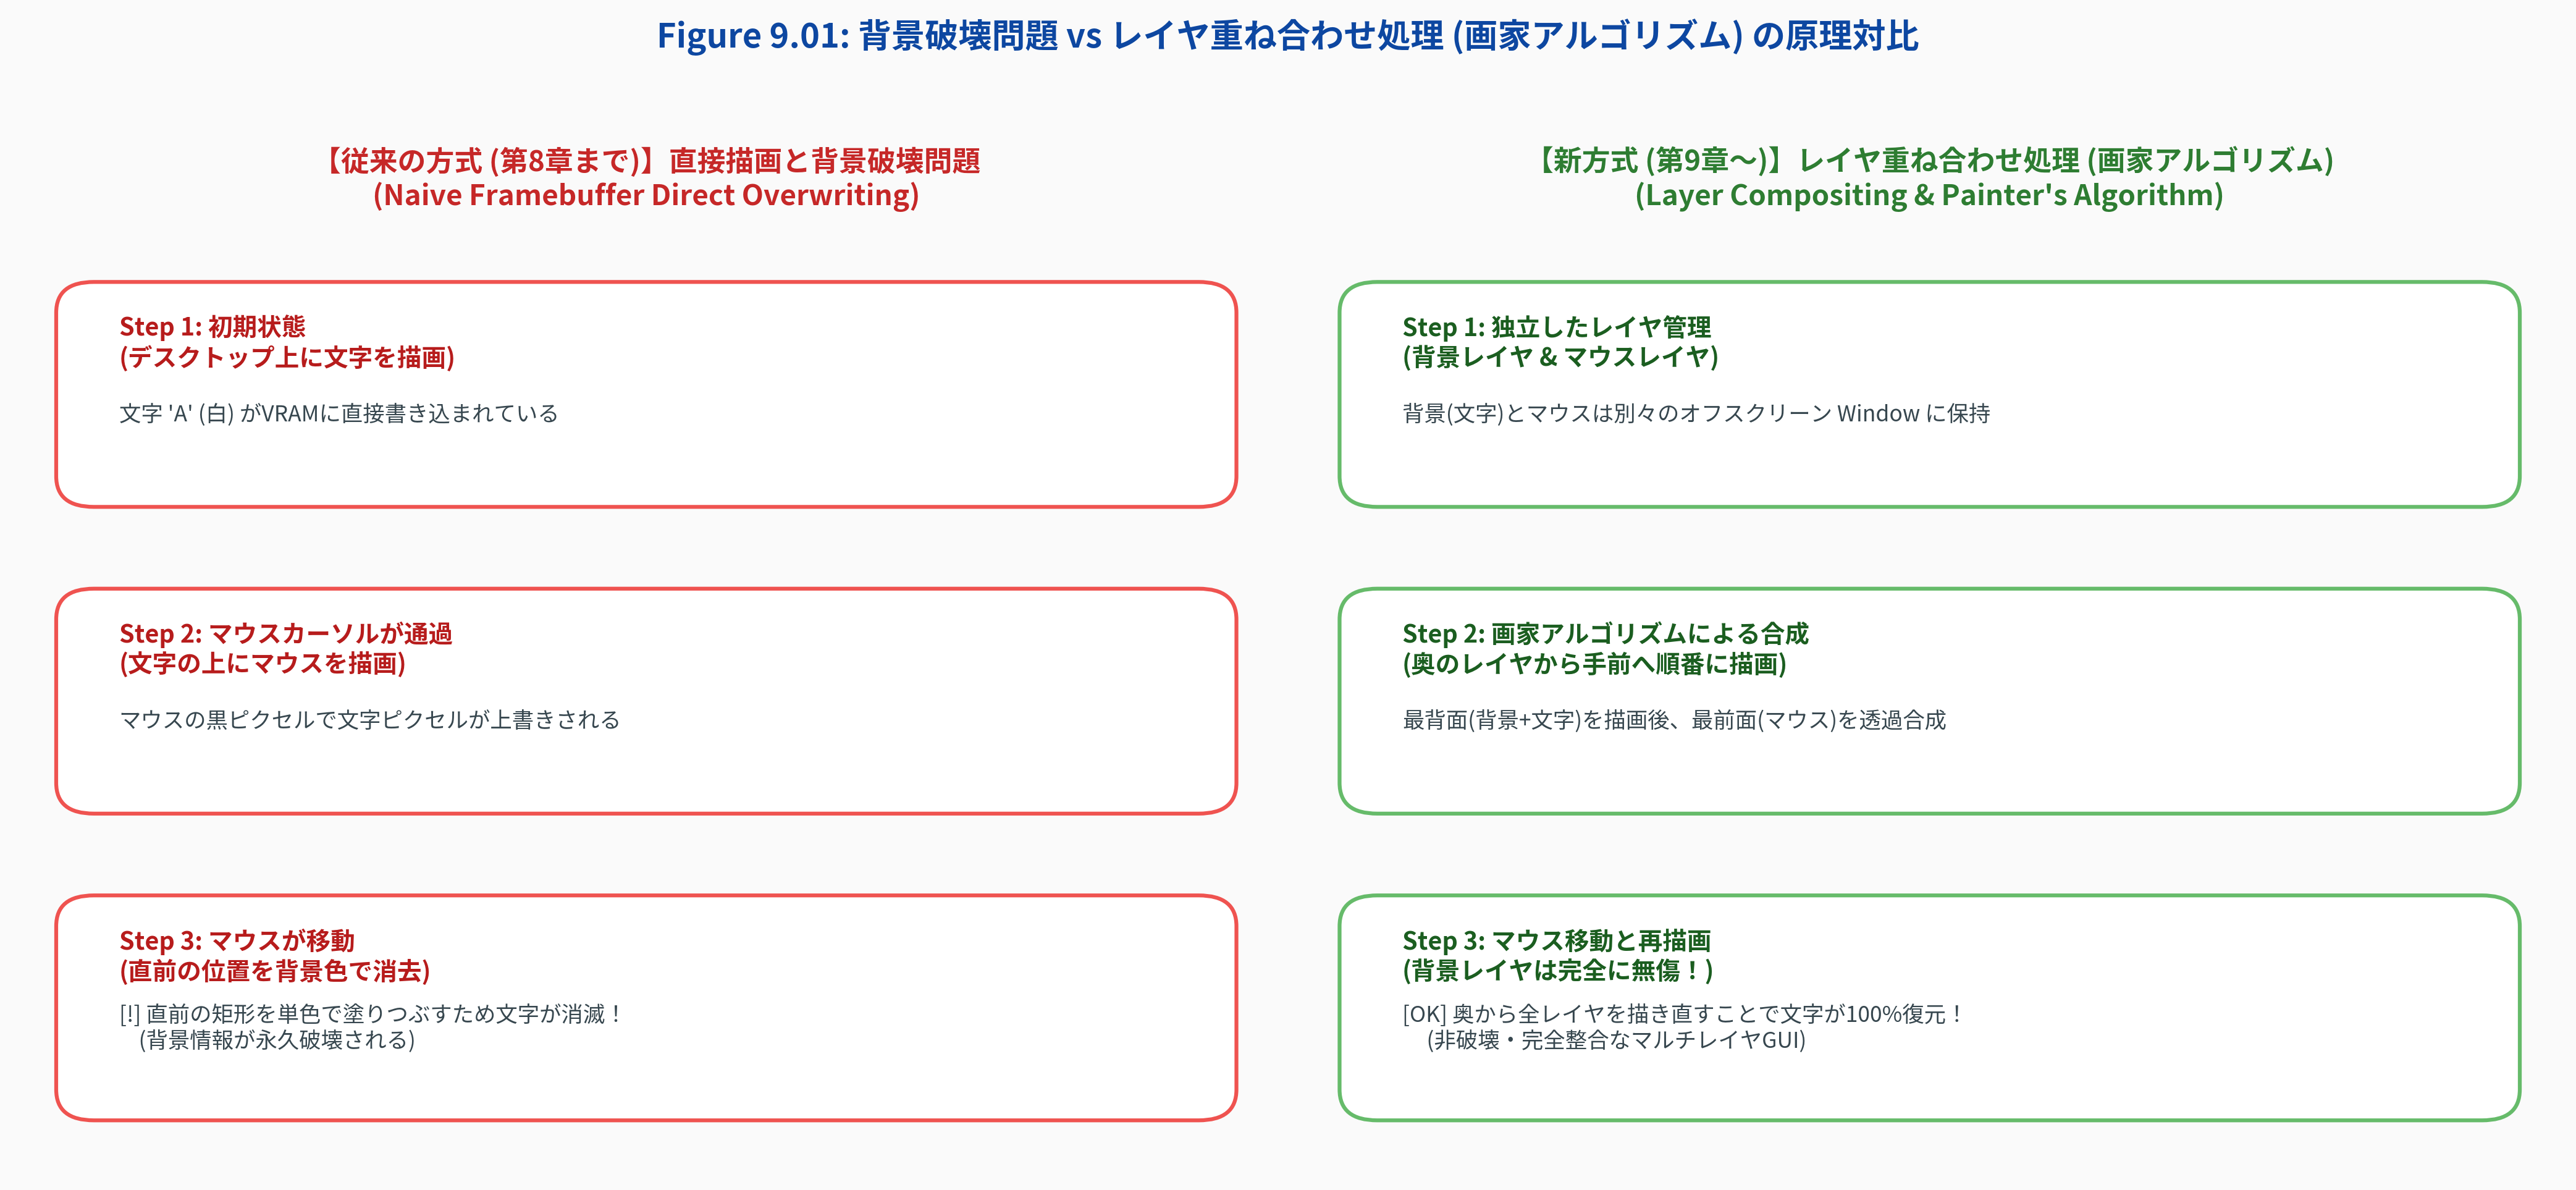

In [2]:
from common import plot_fig9_01_background_destruction_vs_layer_compositing
from IPython.display import Image, display

fig9_01_path = plot_fig9_01_background_destruction_vs_layer_compositing()
display(Image(filename=str(fig9_01_path)))


---

## 2. MikanOS のレイヤ合成アーキテクチャ (`osbook_day09a`)

MikanOS では、この重ね合わせ処理を実現するために、責務が明確に分離された **3つのコアクラス（`Window`, `Layer`, `LayerManager`）** および座標構造体 **`Vector2D<T>`** を導入しました。

```
                    ┌───────────────────────────────────────────────┐
                    │                 LayerManager                  │
                    │ ┌───────────────────────────────────────────┐ │
                    │ │ writer_: PixelWriter*                     │ │
                    │ │ layers_: vector<unique_ptr<Layer>>        │ │
                    │ │ layer_stack_: vector<Layer*> (Z-order)    │ │
                    │ └───────────────────────────────────────────┘ │
                    └───────┬───────────────────────────────┬───────┘
                            │ 所有 (1..N)                   │ 描画順管理
                            ▼                               ▼
                 ┌──────────────────────┐        ┌──────────────────────┐
                 │       Layer 1        │        │       Layer 2        │
                 │ ┌──────────────────┐ │        │ ┌──────────────────┐ │
                 │ │ id_: 1           │ │        │ │ id_: 2           │ │
                 │ │ pos_: (0, 0)     │ │        │ │ pos_: (200, 150) │ │
                 │ │ window_: ───┐    │ │        │ │ window_: ───┐    │ │
                 │ └─────────────┼────┘ │        │ └─────────────┼────┘ │
                 └───────────────┼──────┘        └───────────────┼──────┘
                                 │ 参照 (shared_ptr)             │ 参照 (shared_ptr)
                                 ▼                               ▼
                     ┌──────────────────────┐        ┌──────────────────────┐
                     │    Window (Desktop)  │        │     Window (Mouse)   │
                     │ ┌──────────────────┐ │        │ ┌──────────────────┐ │
                     │ │ width: 1024      │ │        │ │ width: 15        │ │
                     │ │ height: 768      │ │        │ │ height: 24       │ │
                     │ │ data_: 2D Pixels │ │        │ │ data_: 2D Pixels │ │
                     │ │ trans_color: None│ │        │ │ trans_color: #63 │ │
                     │ └──────────────────┘ │        │ └──────────────────┘ │
                     └──────────────────────┘        └──────────────────────┘
```

### (1) `Vector2D<T>`: 2次元座標ベクトル
```cpp
template <typename T>
struct Vector2D {
  T x, y;

  template <typename U>
  Vector2D<T>& operator+=(const Vector2D<U>& rhs) {
    x += rhs.x; y += rhs.y; return *this;
  }
};
```
- マウスの移動変位（`displacement_x`, `displacement_y`）やウィンドウの絶対位置を型安全かつ直感的に加減算できるテンプレート構造体です。

### (2) `Window`: オフスクリーンピクセルバッファ
- タイトルバー付きの典型的なウィンドウだけでなく、**「デスクトップ背景」や「マウスカーソル」も含めて、画面に表示されるすべての矩形グラフィック要素を `Window` としてモデル化**します。
- `data_`: `std::vector<std::vector<PixelColor>>` による2次元ピクセル格納バッファ。
- `transparent_color_`: `std::optional<PixelColor>` による透過色設定。マウスカーソルなど、矩形枠のうち背景を透かしたい部分のキーカラーを指定します。
- `WindowWriter`: `Window` の内部クラスであり、`PixelWriter` インターフェースを実装。これにより、既存の文字描画関数（`WriteString`）や矩形描画関数（`FillRectangle`）を一切書き換えることなく、直接 `Window` に対して描画できます。

### (3) `Layer`: レイヤの属性管理
- 1つの `Window` に対する参照（`std::shared_ptr<Window> window_`）と、画面上の表示位置（`Vector2D<int> pos_`）、固有の `id_` を管理します。
- `Move(pos)` や `MoveRelative(diff)` により、ピクセルデータを再描画することなく座標だけを瞬時に変更できます。

### (4) `LayerManager`: 重ね合わせと重なり順（Z-order）の調停者
- `layers_`: 生成されたすべてのレイヤの実体を `std::vector<std::unique_ptr<Layer>>` で排他所有（所有権の管理）。
- `layer_stack_`: 現在表示中のレイヤを生ポインタ（`Layer*`）の配列として、**奥から手前へ並べたスタック（描画順序の管理）**。
- `UpDown(id, new_height)`: レイヤの重なり順（高さ）を動的に変更。
- `Draw()`: `layer_stack_` を先頭（最背面）から末尾（最前面）に向かって走査し、各レイヤの `DrawTo()` を呼び出すことで画家アルゴリズム合成を実行します。

---

### Figure 9.02: レイヤ合成アーキテクチャとデータ構造関連図


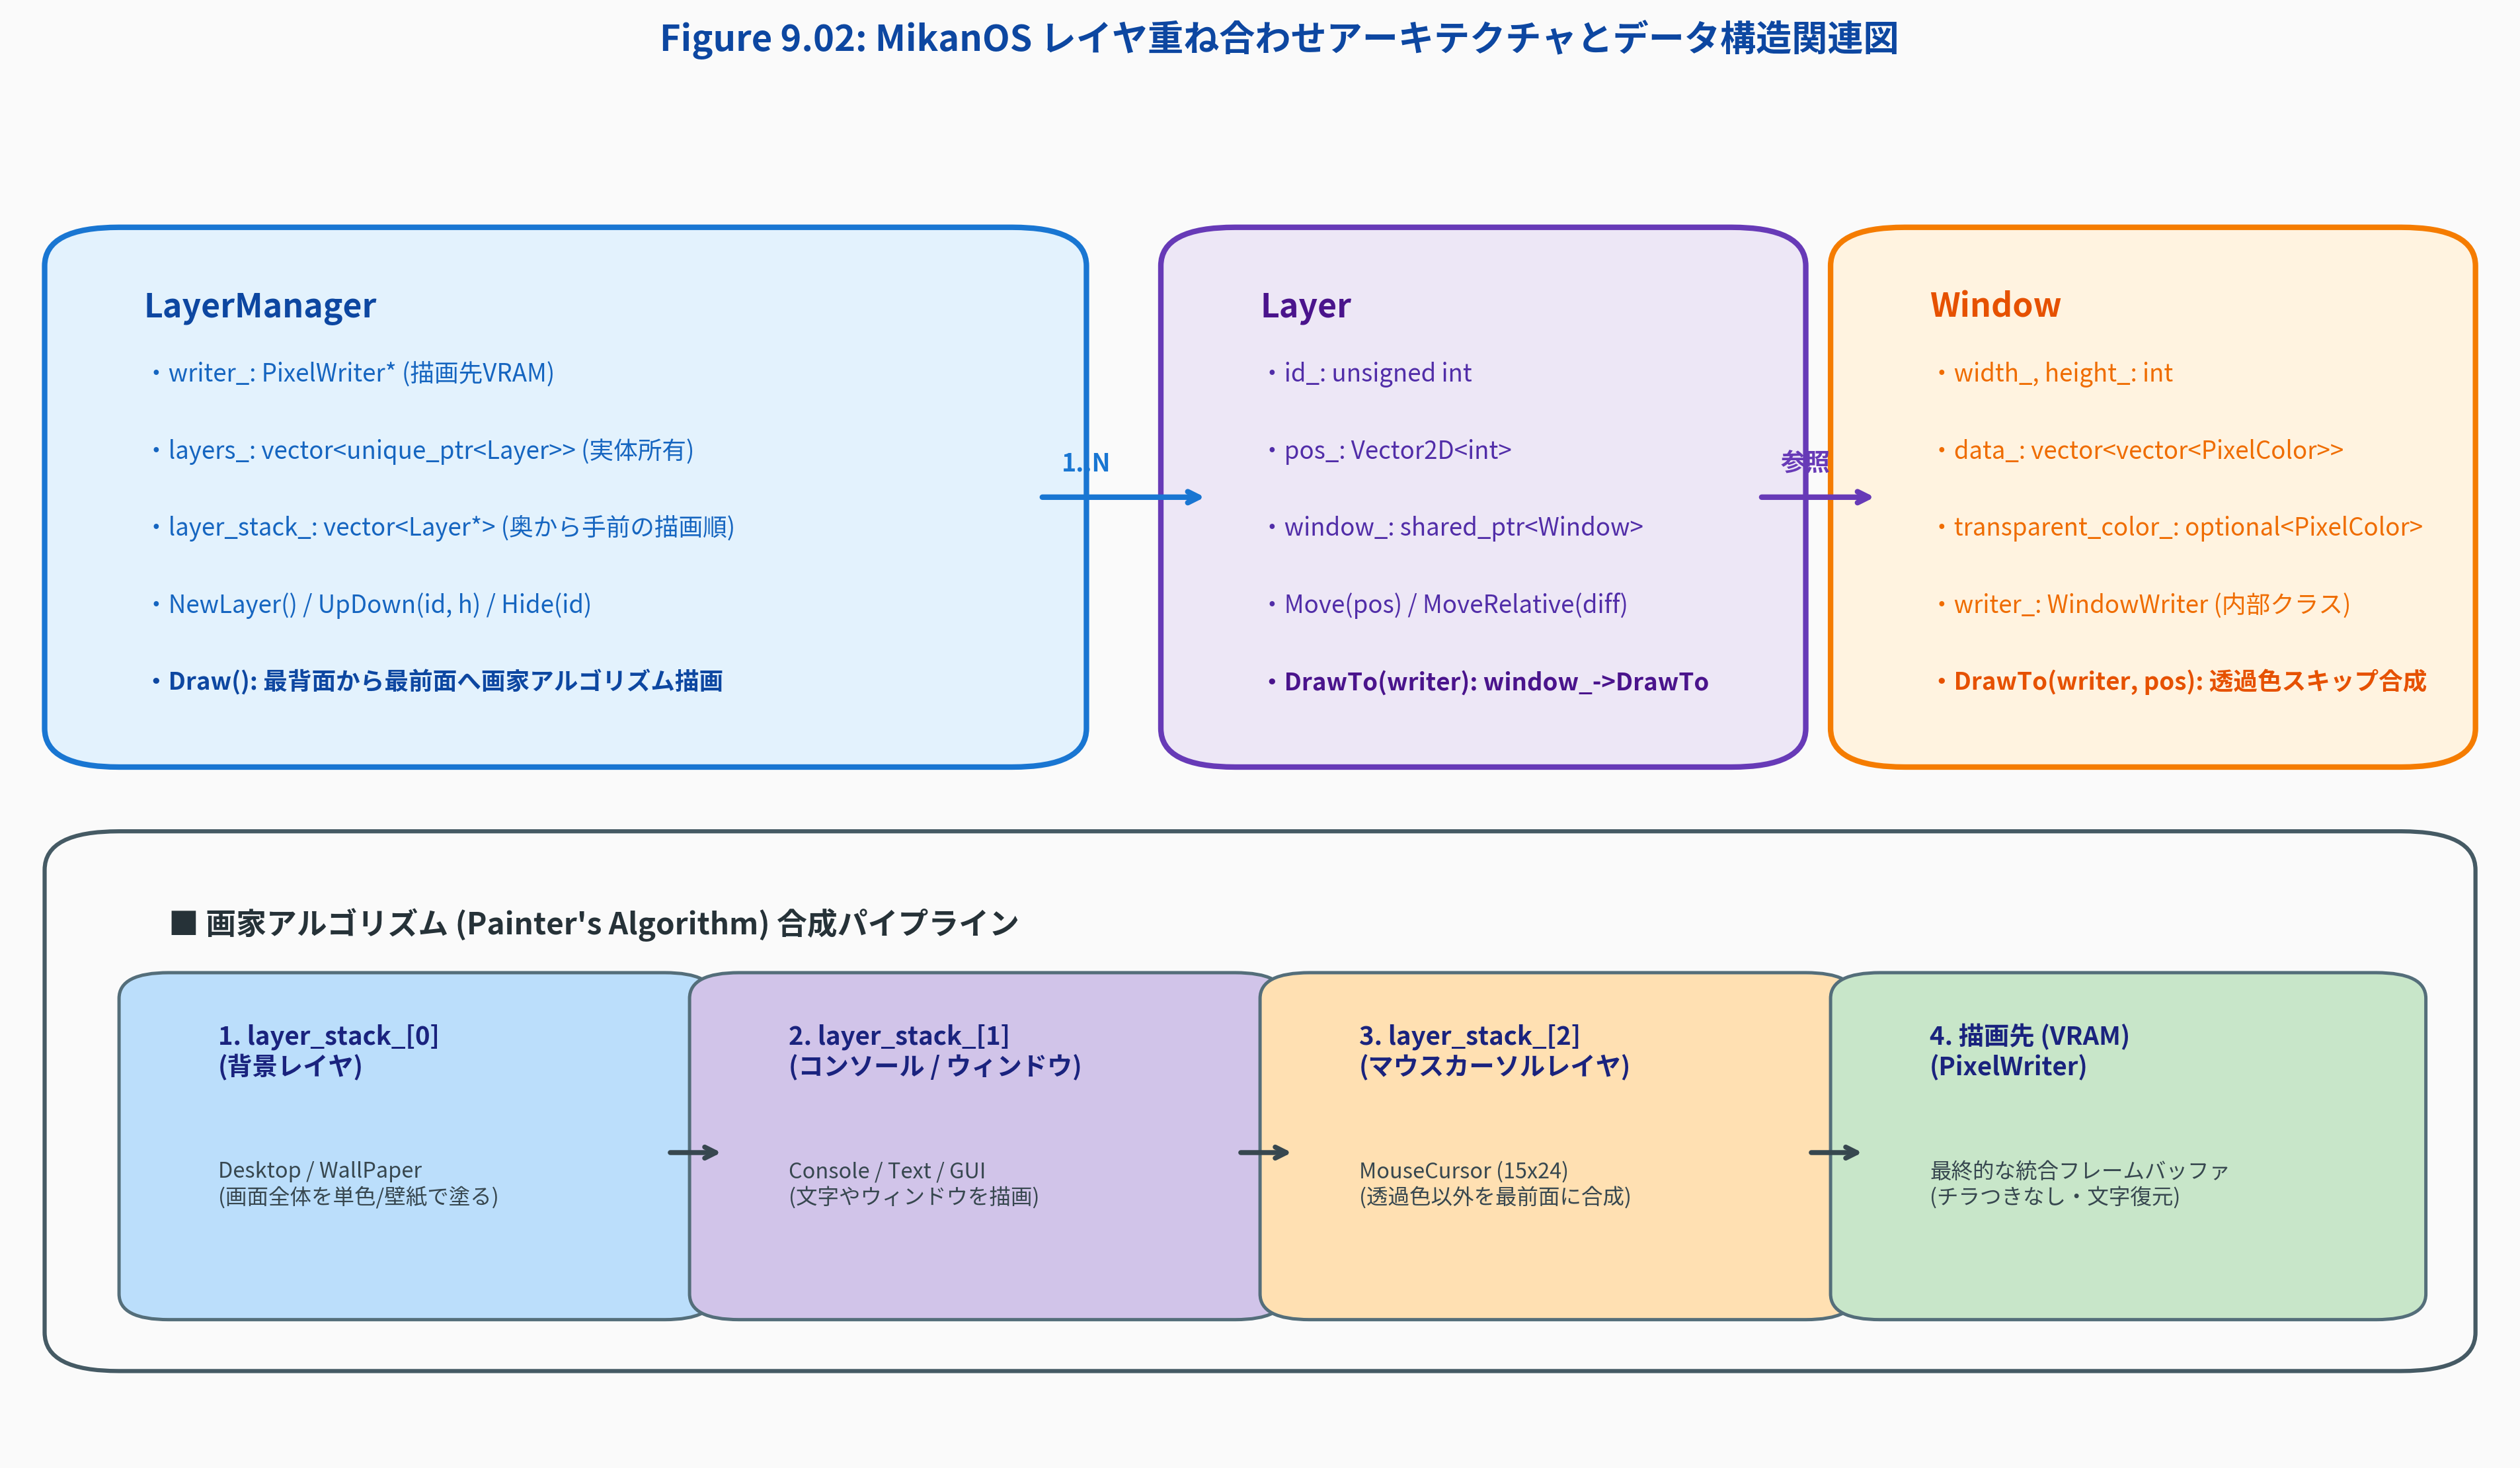

In [3]:
from common import plot_fig9_02_layer_compositing_architecture
from IPython.display import Image, display

fig9_02_path = plot_fig9_02_layer_compositing_architecture()
display(Image(filename=str(fig9_02_path)))


---

## 3. レイヤ合成の数理とアルゴリズム導出

### 1. 座標変換数理
レイヤが画面上の絶対座標 $\mathbf{P} = (p_x, p_y)$ に配置されているとき、ウィンドウ内のローカルピクセル座標 $(w_x, w_y)$（$0 \le w_x < W_{\text{win}}, 0 \le w_y < H_{\text{win}}$）は、フレームバッファ（画面）上のスクリーン座標 $(s_x, s_y)$ に次のように線形写像されます：

$$s_x = p_x + w_x, \quad s_y = p_y + w_y$$

### 2. 画面クリッピング（Screen Clipping）の条件
ウィンドウの一部が画面外（負の座標や解像度超過）にはみ出した場合、そのまま VRAM アドレスを計算して書き込むと領域外アクセス（メモリ破壊や Page Fault）を引き起こします。
画面解像度を $W_{\text{scr}} \times H_{\text{scr}}$ とするとき、書き込みを許可するピクセルの必要十分条件は以下の通りです：

$$0 \le s_x < W_{\text{scr}} \quad \land \quad 0 \le s_y < H_{\text{scr}}$$

この不等式をウィンドウローカル座標 $(w_x, w_y)$ について解くと、実際に走査・描画すべきクリッピング範囲が厳密に求まります：

$$\max(0, -p_x) \le w_x < \min(W_{\text{win}}, W_{\text{scr}} - p_x)$$
$$\max(0, -p_y) \le w_y < \min(H_{\text{win}}, H_{\text{scr}} - p_y)$$

### 3. カラーキーイング（Color Keying / 透過色スキップ）の数理
透過色を $C_{\text{trans}} = (R_t, G_t, B_t)$、ウィンドウ内のピクセル色を $C_{\text{win}}(w_x, w_y)$ とすると、描画先 VRAM ピクセル $C_{\text{scr}}(s_x, s_y)$ の合成規則はディラックのデルタ的な条件分岐として定義されます：

$$C_{\text{scr}}(s_x, s_y) \leftarrow \begin{cases} C_{\text{win}}(w_x, w_y) & (C_{\text{win}}(w_x, w_y) \ne C_{\text{trans}}) \\ C_{\text{scr}}(s_x, s_y) \quad \text{(既存ピクセルをそのまま保持)} & (C_{\text{win}}(w_x, w_y) = C_{\text{trans}}) \end{cases}$$

### 4. `UpDown(id, new_height)` のスタック操作数理
`LayerManager::UpDown` は、指定されたレイヤをスタック内の指定位置（高さ）へ再配置します：
- **$h < 0$**: レイヤを非表示にする（`Hide(id)` を呼び出し、`layer_stack_` から除外）。
- **$h \ge |\text{stack}|$**: 最前面へ配置（スタックの末尾へ挿入）。
- **$0 \le h < |\text{stack}|$**: 既存の位置から削除後、インデックス $h$ へ挿入。

---

### Figure 9.03: UpDown 操作による重なり順制御とレイヤスタック状態遷移


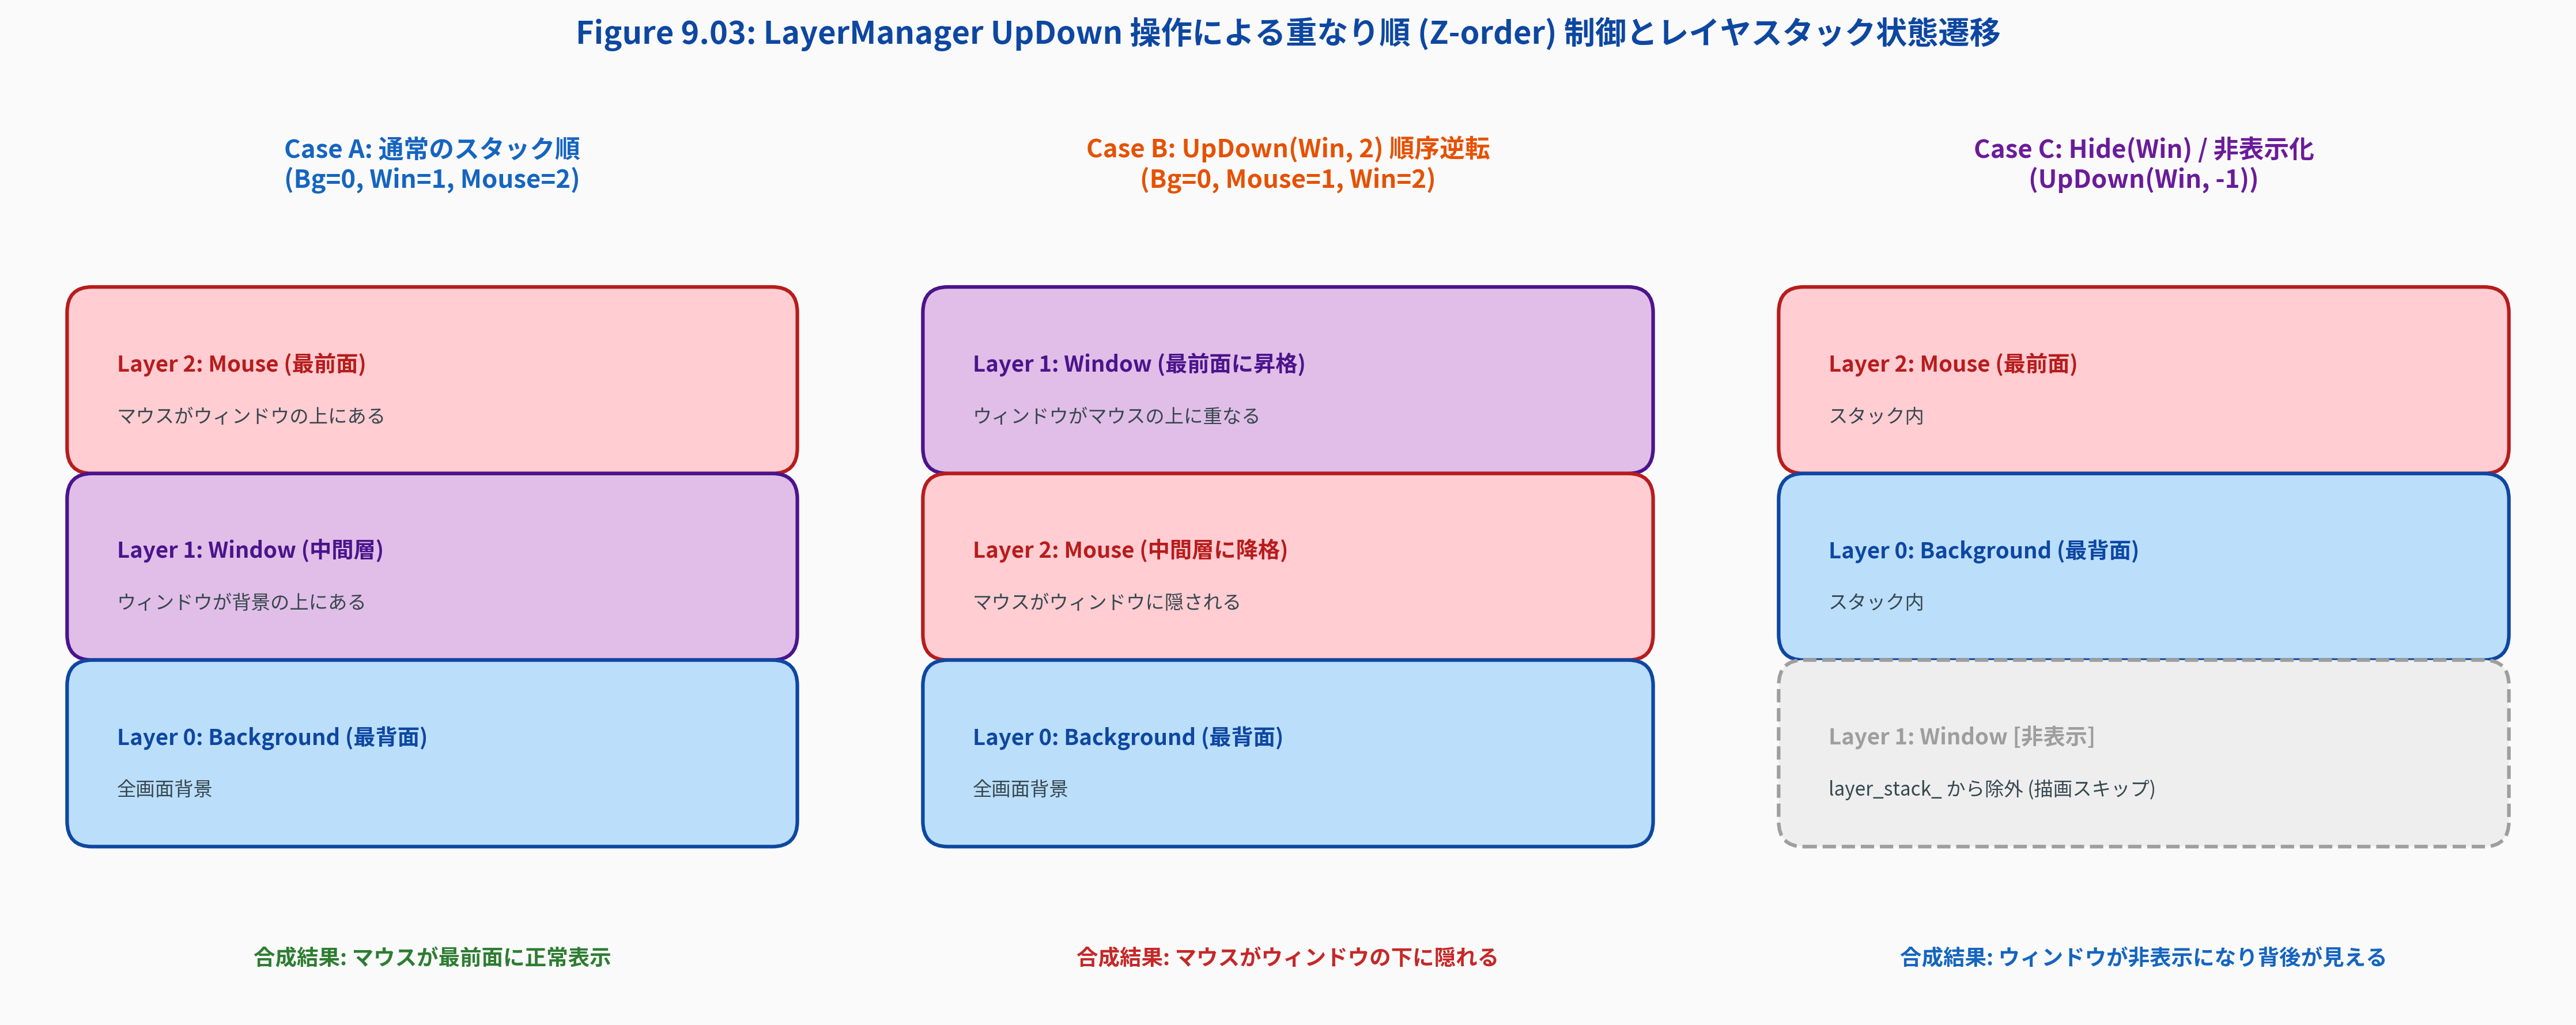

In [4]:
from common import plot_fig9_03_layer_stack_updown_and_compositing_order
from IPython.display import Image, display

fig9_03_path = plot_fig9_03_layer_stack_updown_and_compositing_order()
display(Image(filename=str(fig9_03_path)))


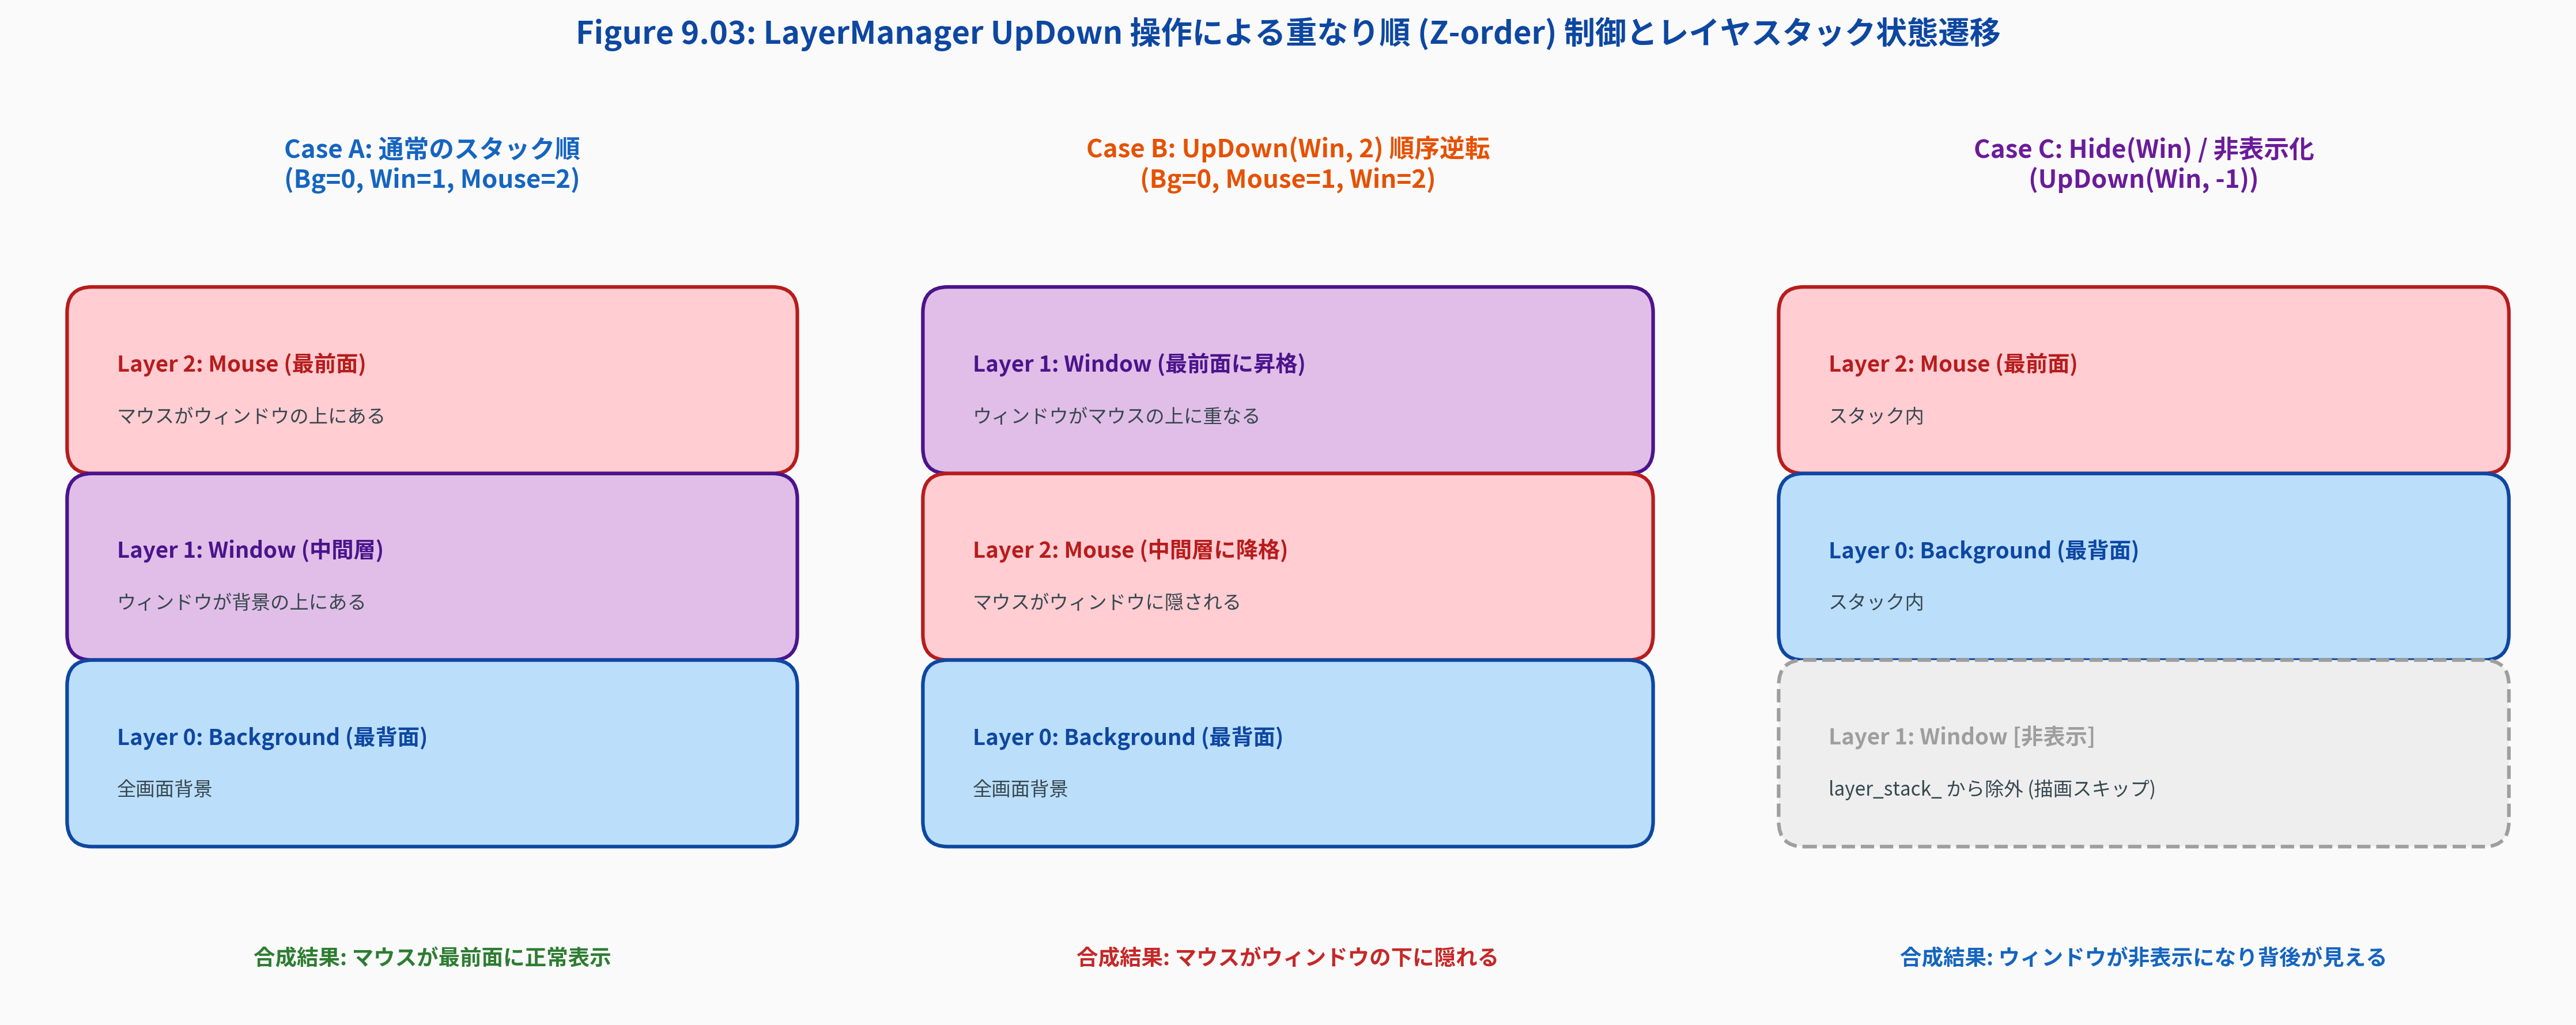

In [5]:
from common import plot_fig9_03_layer_stack_updown_and_compositing_order
from IPython.display import Image, display

fig9_03_path = plot_fig9_03_layer_stack_updown_and_compositing_order()
display(Image(filename=str(fig9_03_path)))


---

## 4. 対話型 C++20 検証コードのコンパイルと実行

MikanOS の `Vector2D`, `Window`, `Layer`, `LayerManager` の実装ロジックをホスト環境（C++20）で完全に検証するスタンドアロンプログラム `src/ch09/os_chapter9_layer_intro.cpp` をコンパイル・実行します。

ここでは以下を自動検証します：
1. `Vector2D<T>` の座標加減算演算子
2. `Window` と `WindowWriter` による描画と透過色スキップ
3. `LayerManager::UpDown` によるレイヤ順序反転時の描画ピクセル変化
4. マウス移動時の背景破壊問題の解消（文字ピクセルが100%保持されることの実証）


In [6]:
import subprocess
res = subprocess.run(
    ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "src/ch09/os_chapter9_layer_intro.cpp", "-o", "/tmp/os_ch9_intro"],
    capture_output=True, text=True
)
if res.returncode != 0:
    print("Compilation error:", res.stderr)
else:
    print("Compilation succeeded! Running tests...\n")
    run_res = subprocess.run(["/tmp/os_ch9_intro", "--test"], capture_output=True, text=True)
    print(run_res.stdout)


Compilation succeeded! Running tests...

 Chapter 9.1: Introduction to Layer Compositing Sim (C++20)
[PASS] Vector2D<T> coordinate operations verified.
[PASS] Window buffer & WindowWriter verified.
[PASS] Window DrawTo with Transparent Color verified.
[PASS] LayerManager UpDown z-order reordering verified.
[PASS] LayerManager Hide and MoveRelative verified.
[PASS] Background destruction completely resolved via Layer Compositing!
✅ All Chapter 9.1 Layer Compositing C++20 tests passed successfully!



---

## 5. Python による背景破壊問題の再現とレイヤ合成シミュレーション

`common.os_sim` に実装した `BackgroundDestructionComparator` を用いて、第8章までの直接上書き方式と第9章のレイヤ合成方式の挙動を定量的に比較します。


In [7]:
from common import BackgroundDestructionComparator

results = BackgroundDestructionComparator.simulate_naive_vs_layer_movement()

print("=" * 60)
print("【マウス移動時の背景ピクセル保持検証 (30x30 ピクセル空間)】")
print("=" * 60)
print(f"1. 従来の直接上書き方式 (Naive Overwriting):")
print(f"   - マウス通過・移動後の文字ピクセル保持: {'[OK] 保持' if results['naive_text_preserved'] else '[FAILED] 破壊・消失 (False)'}")
print()
print(f"2. レイヤ重ね合わせ方式 (Layer Compositing):")
print(f"   - マウス通過・移動後の文字ピクセル保持: {'[OK] 完全保持 (True)' if results['layer_text_preserved'] else '[FAILED]'}")
print(f"   - Step 1 マウス描画時のカーソル表示:     {'[OK] 正常' if results['layer_step1_cursor'] else '[FAILED]'}")
print(f"   - Step 2 移動後の新位置カーソル描画:     {'[OK] 正常' if results['cursor_new_pos_correct'] else '[FAILED]'}")
print("=" * 60)


【マウス移動時の背景ピクセル保持検証 (30x30 ピクセル空間)】
1. 従来の直接上書き方式 (Naive Overwriting):
   - マウス通過・移動後の文字ピクセル保持: [FAILED] 破壊・消失 (False)

2. レイヤ重ね合わせ方式 (Layer Compositing):
   - マウス通過・移動後の文字ピクセル保持: [OK] 完全保持 (True)
   - Step 1 マウス描画時のカーソル表示:     [OK] 正常
   - Step 2 移動後の新位置カーソル描画:     [OK] 正常


---

## 6. 対話型マルチレイヤ合成ビューア（Python / matplotlib）

実際に 3つのレイヤ（デスクトップ背景、コンソールウィンドウ、マウスカーソル）を `LayerManagerSim` に登録し、レイヤ合成のフレームバッファ結果をプロットします。


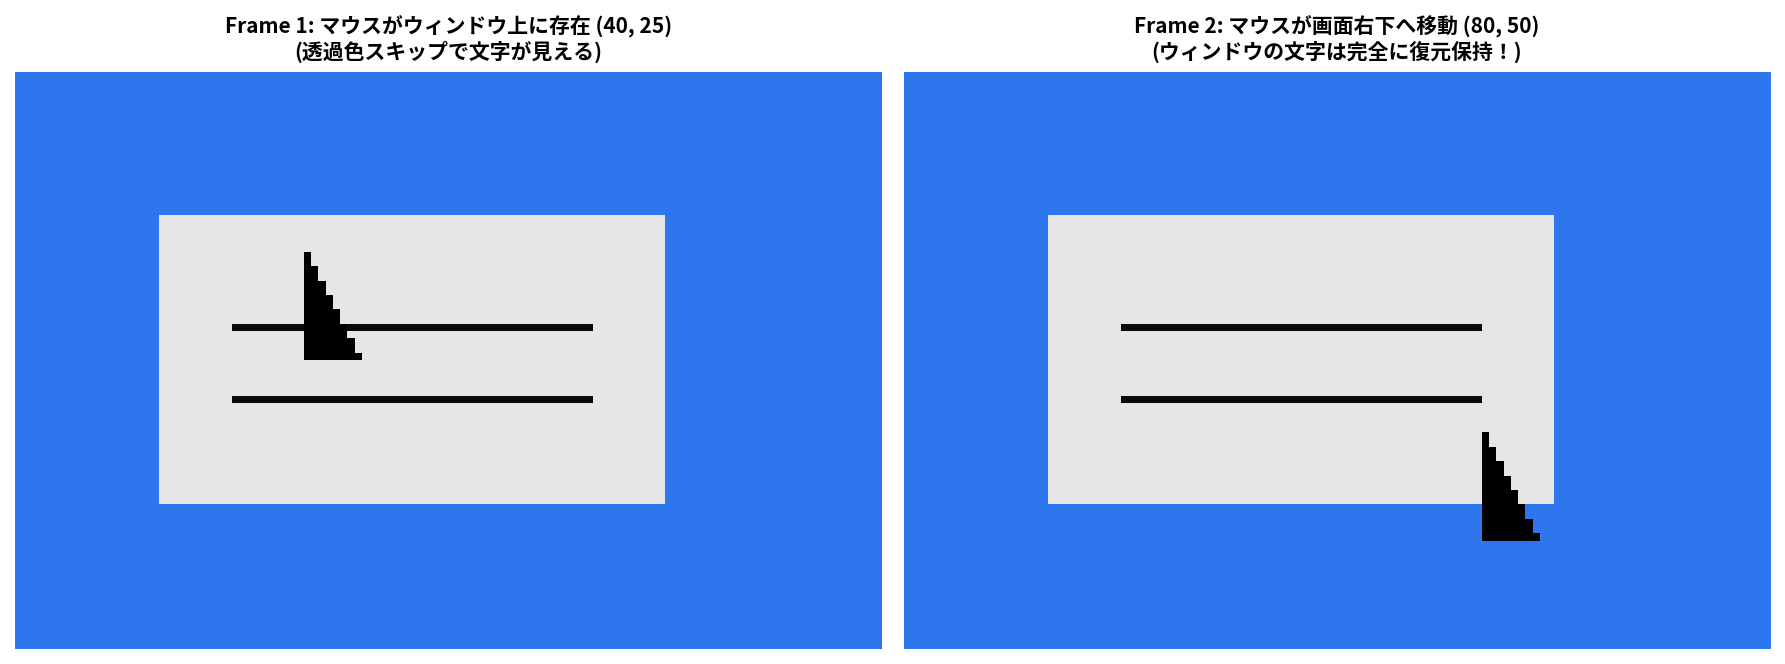

In [8]:
import matplotlib.pyplot as plt
from common import Vector2DSim, PixelColorSim, WindowSim, LayerManagerSim

# 120x80 のミニ画面をシミュレート
W, H = 120, 80
c_bg = PixelColorSim(45, 118, 237)      # Desktop blue
c_win_bg = PixelColorSim(230, 230, 230) # Window gray
c_text = PixelColorSim(10, 10, 10)      # Text dark
c_mouse_core = PixelColorSim(0, 0, 0)   # Mouse black
c_trans = PixelColorSim(255, 0, 255)    # Magenta transparent key

mgr = LayerManagerSim(W, H, c_bg)

# Layer 0: Desktop Background
win_bg = WindowSim(W, H, c_bg)
l_bg = mgr.new_layer().set_window(win_bg).move(Vector2DSim(0, 0))

# Layer 1: Window with mock text
win_gui = WindowSim(70, 40, c_win_bg)
for x in range(10, 60):
    win_gui.write(x, 15, c_text) # Text line 1
    win_gui.write(x, 25, c_text) # Text line 2
l_gui = mgr.new_layer().set_window(win_gui).move(Vector2DSim(20, 20))

# Layer 2: Mouse cursor (10x15) with transparency
win_mouse = WindowSim(10, 15, c_trans)
win_mouse.set_transparent_color(c_trans)
for y in range(15):
    for x in range(y // 2 + 1):
        win_mouse.write(x, y, c_mouse_core)
l_mouse = mgr.new_layer().set_window(win_mouse).move(Vector2DSim(40, 25))

# UpDown
mgr.up_down(l_bg.id, 0)
mgr.up_down(l_gui.id, 1)
mgr.up_down(l_mouse.id, 2)

# Initial draw
mgr.draw()
frame_a = mgr.to_numpy_array()

# Move mouse to new position (80, 50) and redraw
mgr.move(l_mouse.id, Vector2DSim(80, 50))
mgr.draw()
frame_b = mgr.to_numpy_array()

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.imshow(frame_a)
ax1.set_title("Frame 1: マウスがウィンドウ上に存在 (40, 25)\n(透過色スキップで文字が見える)", fontsize=10, fontweight="bold")
ax1.axis("off")

ax2.imshow(frame_b)
ax2.set_title("Frame 2: マウスが画面右下へ移動 (80, 50)\n(ウィンドウの文字は完全に復元保持！)", fontsize=10, fontweight="bold")
ax2.axis("off")

plt.tight_layout()
plt.show()


---

## 7. OS 自作における重ね合わせ処理の実装上の落とし穴

### 落とし穴 1: `layer_stack_` 操作時のイテレータ無効化（Iterator Invalidation）
`LayerManager::UpDown` では、指定されたレイヤを `layer_stack_` 内で移動させるため、`erase()` と `insert()` を行います。
```cpp
auto old_pos = std::find(layer_stack_.begin(), layer_stack_.end(), layer);
auto new_pos = layer_stack_.begin() + new_height;

if (old_pos == layer_stack_.end()) {
  layer_stack_.insert(new_pos, layer);
  return;
}

if (new_pos == layer_stack_.end()) {
  --new_pos;
}
layer_stack_.erase(old_pos);
layer_stack_.insert(new_pos, layer); // ⚠️ 危険！
```
- **解説**: `std::vector::erase(old_pos)` を呼ぶと、それ以降のすべてのイテレータが無効化（Invalidate）されます。もし `old_pos < new_pos` であった場合、`erase` によって要素が前へ詰められるため、あらかじめ計算していた `new_pos` の指す位置が1つずれてしまいます。
- **MikanOS の対処法**: `osbook_day09a` では `new_pos` を `erase` 後に再計算するか、要素のインデックス（整数値）で位置関係を調整することで安全性を担保しています。

### 落とし穴 2: 符号なし型（unsigned）による画面外クリッピングの失敗
マウスカーソルが画面の左上（$x < 0$ や $y < 0$）へはみ出した場合、座標計算において `int` と `unsigned int`（または `size_t`）の暗黙の型変換が混ざると、`-1` が `0xFFFFFFFF`（巨大な正数）として解釈されてクリッピングをすり抜けてしまいます。
結果として、画面外の任意のアドレスへ VRAM 書き込みが発生し、カーネルのデータ構造を破壊したり Page Fault 例外でハングアップします。
**座標は必ず符号付き整数（`int`）で扱い、境界判定を厳格に行うことが鉄則**です。

### 落とし穴 3: 全画面再描画による性能ボトルネック（次節への課題）
`osbook_day09a` の `LayerManager::Draw()` は、マウスが 1 ピクセル動くだけで**全レイヤの全ピクセルを最背面からすべて VRAM に上書き転送（全画面再描画）**します。
- 解像度 $1024 \times 768$、32bpp（4バイト/ピクセル）の場合、画面1枚で約 $3.15 \text{MB}$。
- レイヤが 3 つあれば、1回のマウス移動で約 $9.45 \text{MB}$ のメモリアクセスが発生します。
- これを USB マウスの報告頻度（1秒間に 100〜1000回）で実行すると、CPU が VRAM 書き込みで 100% 飽和し、激しい描画遅延と画面のチラつき（Flickering）が発生します。
- この問題の解決策（**矩形交差判定による差分再描画最適化**）こそが、第9章後半（9.4〜9.5節）の主要テーマとなります！


---

## 8. まとめと次節（9.2 new演算子）への展望

### 本節のまとめ
1. **背景破壊問題の解決**:
   - マウス移動時に背景を単色塗りつぶし消去する方式では背景の文字やウィンドウが永久破壊される。
   - 画面要素を独立したレイヤ（Layer）に分割し、奥から手前に描画する「画家アルゴリズム」によって背景破壊を完全に解決した。
2. **3大クラスによるアーキテクチャ**:
   - `Window`: 2次元ピクセル配列、透過色キー、`WindowWriter`。
   - `Layer`: 位置座標 `pos_`、`Window` への `shared_ptr`。
   - `LayerManager`: レイヤ所有 `layers_`、重なり順スタック `layer_stack_`、`UpDown` / `Draw`。
3. **カラーキーイングと透過合成**:
   - マウスカーソルの透明色（`kMouseTransparentColor`）をスキップすることで、自然なカーソル形状の合成を実現した。

### 次節（9.2 new演算子）への展望
本節で設計した `Window` や `Layer`、そしてコンテナ `std::vector` やスマートポインタ `std::shared_ptr` / `std::unique_ptr` をカーネル内で自由自在に生成・破棄するためには、**C++ の動的メモリ確保機構（`new` / `delete` 演算子）**が必須です。
しかし、OS のベアメタル環境には標準のヒープ領域やアロケータ（`malloc` / `free`）が最初から存在しているわけではありません！

次節 **9.2「new演算子」** では、第8章で作成した `BitmapMemoryManager` から物理メモリを切り出し、C標準ライブラリ（Newlib）のシステムコール低水準実装 `sbrk()` をカーネル内に構築することで、カーネル内で `new` 演算子と C++ STL コンテナを本格稼働させる旅に出発します！
